# Do the confirmed fixes stack on ImageNet-C and DomainNet?

**Question.** Two kinds of fix beat Ramen separately. (a) Output fixes: *prior correction* (pc) and causal *kNN smoothing* (knn), +2.07 on CIFAR-100-C and +7.02 on EuroSAT together, never tried with kNN on the large-label datasets. (b) The *zero-shot-weighted active set* at T=3 (T3), +0.62 on ImageNet-C and +0.24 on DomainNet, which helps only with many classes. Do they add up on the two large-label datasets?

**Hypothesis.** T3 + knn + pc beats Ramen by more than the noise floor on both datasets: > 0.53 pts on ImageNet-C 5K, > 0.11 on DomainNet (domain-averaged accuracy, mean over seeds 0–4).

**Why this test.** pc and knn transform a run's output probabilities only. Ramen files each image under its *zero-shot* prediction and caches gradients taken at the base weights, so its outputs never feed back into its memory. The stack is therefore an exact offline transform of a saved run, with no new method code. The only GPU work is re-running Ramen and T3 with the full softmax saved (the earlier runs kept only the top prediction).

**Variants** (none uses true labels; labels are used only to score):

| Name | What it is |
|---|---|
| Ramen | baseline, `cfg/<ds>/Ramen.yaml` |
| T3 | RamenActive, `active_set: prob`, `temperature: 3`: each class queue's vote weighted by the query's zero-shot probability^(1/3) |
| + pc | logit − λ·log(π_t / uniform), π_t = EMA (m = 0.99) of the predicted class marginal, updated batch by batch including the current batch; λ = 2 |
| + knn | 0.5·p + 0.5·(weighted mean of p over the K = 10 most similar images from *earlier* batches; similarity = zero-shot CLIP feature dot product, weights softmax(sim / 0.01)) |
| + knn + pc | knn first, then pc (the order used on CIFAR / EuroSAT) |
| + pc(λ=1), pc(λ=0.5) | **post-hoc**: λ = 2 with a uniform target hurt DomainNet before (−0.53), so smaller λ are reported, labelled post-hoc |

All settings (λ = 2, m = 0.99, K = 10, temperature 0.01, mix 0.5, T = 3) were fixed on CIFAR / ImageNet-C before this experiment: **pre-registered**. T = 3 was tuned on ImageNet-C seed 0, so T3 on ImageNet-C is not held-out; on DomainNet it is.

**Data.** ImageNet-C 5K (15 corruptions × 5,000 images, severity 5, 997 classes, CLIP ViT-B/16) and DomainNet (6 domains, 596,006 images, 345 classes, CLIP ViT-B/32), one shuffled mixed stream each, batches of 100.

**Seeds.** 0–4. A seed sets the stream order (and Ramen's selection randomness); the images are the same. NoAdapt (zero-shot) is stateless, so its features from seed 0 are realigned to every seed by (domain, image id).

**How the runs were produced.** `bash run_queue.sh` (detached, one worker per GPU) runs `run_probs.py <ds> <seed> <Ramen|active_prob_T3>`. It saves `results/<ds>_..._s<seed>_<variant>_p.{pkl,_probs.npy}` and never overwrites the cached runs. Seed-0 Ramen probabilities were already cached. Then `python stack.py <ds> 0 1 2 3 4` writes `results/stacking/<ds>_s<seed>_{stack,per_domain,knn_diag}.csv`.

**What counts as a result.** Mean gain over Ramen above the noise floor, 2 × (max − min) of Ramen's accuracy over seeds 0–4: **0.53** (ImageNet-C), **0.11** (DomainNet). Also reported: per-seed gains, seeds positive, and per-seed cluster-bootstrap 95% CIs (clusters = base image on ImageNet-C, image on DomainNet).

**How to read this notebook.** 1 Setup · 2 Data · 3 Sanity checks · 4 Results (pre-registered) · 5 Does the stack add up? · 6 Per domain · 7 Post-hoc λ · 8 Mechanism: what kNN averages over · 9 Interpretation · 10 Glossary

## 1. Setup

In [1]:
import os, sys
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import stack
from stack import collect, seed_summary, additivity, NOISE_FLOOR, LABEL
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
DATASETS = os.environ.get('STACK_DATASETS', 'ImageNetC5K,DomainNet').split(',')
tables = {ds: collect(ds) for ds in DATASETS}
{ds: sorted(t.seed.unique()) for ds, t in tables.items()}

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'ImageNetC5K': [np.int64(0),
  np.int64(1),
  np.int64(2),
  np.int64(3),
  np.int64(4)],
 'DomainNet': [np.int64(0),
  np.int64(1),
  np.int64(2),
  np.int64(3),
  np.int64(4)]}

## 2. The data the code ran on

Denominators for everything below. Accuracies are domain-averaged unless stated; counts are pooled.

In [2]:
stack.data_table(DATASETS)

,ImageNet-C 5K,DomainNet
model,clip_vitbase16,clip_vitbase32
images,"75,000","596,006"
domains,15,6
images per domain,"5,000 each","48,833 to 175,327"
classes,997,345
batches of 100,750,"5,961"
NoAdapt correct,"20,468 of 75,000 (27.3%)","314,845 of 596,006 (52.8%)"
Ramen correct (seed 0),"24,809 of 75,000 (33.1%)","324,966 of 596,006 (54.5%)"
NoAdapt acc (domain-avg),27.29,55.37
"Ramen acc (domain-avg, seed 0)",33.08,56.8


In [3]:
fl = {ds: stack.floor(ds) for ds in DATASETS}
pd.DataFrame({LABEL[ds]: {**{f'Ramen seed {s}': round(a, 3) for s, a in enumerate(accs)}, 'range': round(max(accs) - min(accs), 3),
              'noise floor (2 x range)': round(f, 2)} for ds, (f, accs) in fl.items()})

,ImageNet-C 5K,DomainNet
Ramen seed 0,33.079,56.797
Ramen seed 1,33.172,56.793
Ramen seed 2,33.016,56.827
Ramen seed 3,32.907,56.809
Ramen seed 4,32.961,56.848
range,0.265,0.055
noise floor (2 x range),0.530,0.110


## 3. Sanity checks

1. Each probability-saving re-run must reproduce the cached run it stands in for: identical stream order and **identical predictions** (100.00%), and the saved probabilities' argmax must equal the saved predictions.
2. `stack.py` re-implements the earlier CIFAR scripts; on CIFAR-100-C seed 0 it gives knn +0.64, pc +1.45, knn + pc +2.11, the same numbers as `quick_checks/knn_seeds.py` (checked when the module was written).

In [4]:
pd.concat({LABEL[ds]: stack.sanity_table(ds) for ds in DATASETS})

seed             run              file  same order             same predictions  probs argmax == pred
ImageNet-C 5K 0     0           Ramen             Ramen        True    75,000 of 75,000 (100.0%)                  True
              1     0  active_prob_T3  active_prob_T3_p        True    75,000 of 75,000 (100.0%)                  True
              2     1           Ramen           Ramen_p        True    75,000 of 75,000 (100.0%)                  True
              3     1  active_prob_T3  active_prob_T3_p        True    75,000 of 75,000 (100.0%)                  True
              4     2           Ramen           Ramen_p        True    75,000 of 75,000 (100.0%)                  True
              5     2  active_prob_T3  active_prob_T3_p        True    75,000 of 75,000 (100.0%)                  True
              6     3           Ramen           Ramen_p        True    75,000 of 75,000 (100.0%)                  True
              7     3  active_prob_T3  active_prob_T3_p        True    75,000 of 75,000 (100.0%)                  True
              8     4           Ramen           Ramen_p        True    75,000 of 75,000 (100.0%)                  True
              9     4  active_prob_T3  active_prob_T3_p        True    75,000 of 75,000 (100.0%)                  True
DomainNet     0     0           Ramen             Ramen        True  596,006 of 596,006 (100.0%)                  True
              1     0  active_prob_T3  active_prob_T3_p        True  596,006 of 596,006 (100.0%)                  True
              2     1           Ramen           Ramen_p        True  596,006 of 596,006 (100.0%)                  True
              3     1  active_prob_T3  active_prob_T3_p        True  596,006 of 596,006 (100.0%)                  True
              4     2           Ramen           Ramen_p        True  596,006 of 596,006 (100.0%)                  True
              5     2  active_prob_T3  active_prob_T3_p        True  596,006 of 596,006 (100.0%)                  True
              6     3           Ramen           Ramen_p        True  596,006 of 596,006 (100.0%)                  True
              7     3  active_prob_T3  active_prob_T3_p        True  596,006 of 596,006 (100.0%)                  True
              8     4           Ramen           Ramen_p        True  596,006 of 596,006 (100.0%)                  True
              9     4  active_prob_T3  active_prob_T3_p        True  596,006 of 596,006 (100.0%)                  True

## 4. Results (pre-registered settings)

Gain over Ramen per seed (points, domain-averaged), then the summary over seeds.

In [5]:
for ds, t in tables.items():
    t0 = t[~t.posthoc]
    print(f'== {LABEL[ds]}: gain over Ramen (pts) per seed')
    print(t0.pivot(index='variant', columns='seed', values='gain').loc[[v for v in ['Ramen'] + stack.MAIN if v in set(t0.variant)]].round(2).to_string(), '\n')

== ImageNet-C 5K: gain over Ramen (pts) per seed
seed                 0     1     2     3     4
variant                                       
Ramen             0.00  0.00  0.00  0.00  0.00
Ramen + knn      -0.09 -0.13 -0.13 -0.13 -0.06
Ramen + pc        0.23  0.09  0.23  0.23  0.04
Ramen + knn + pc -0.44 -0.40 -0.34 -0.24 -0.40
T3                0.51  0.51  0.73  0.72  0.63
T3 + knn          0.40  0.30  0.40  0.51  0.48
T3 + pc           0.59  0.65  0.79  0.82  0.72
T3 + knn + pc    -0.17 -0.09  0.09  0.07  0.02 

== DomainNet: gain over Ramen (pts) per seed
seed                 0     1     2     3     4
variant                                       
Ramen             0.00  0.00  0.00  0.00  0.00
Ramen + knn       0.19  0.17  0.22  0.21  0.21
Ramen + pc       -0.53 -0.49 -0.52 -0.54 -0.52
Ramen + knn + pc -1.01 -0.98 -0.98 -0.99 -1.02
T3                0.25  0.25  0.25  0.23  0.22
T3 + knn          0.19  0.23  0.23  0.23  0.23
T3 + pc          -0.19 -0.15 -0.20 -0.18 -0.24
T3 + knn + 

In [6]:
pd.concat({LABEL[ds]: seed_summary(ds, t[~t.posthoc]).astype({'gain mean': float, 'gain std': float, 'gain min': float,
           'images vs Ramen': float, 'fixed vs Ramen': float, 'broken vs Ramen': float}).round(2) for ds, t in tables.items()})

seeds  gain mean  gain std  gain min positive above floor mean above floor  images vs Ramen  fixed vs Ramen  broken vs Ramen post-hoc
ImageNet-C 5K Ramen + knn          5      -0.11      0.03     -0.13      0/5         0/5            False            -81.0          1510.8           1591.8    False
              Ramen + pc           5       0.16      0.09      0.04      5/5         0/5            False            121.8          3237.0           3115.2    False
              Ramen + knn + pc     5      -0.36      0.08     -0.44      0/5         0/5            False           -273.4          3913.6           4187.0    False
              T3                   5       0.62      0.11      0.51      5/5         3/5             True            465.6          2672.0           2206.4    False
              T3 + knn             5       0.42      0.08      0.30      5/5         0/5            False            313.4          3093.8           2780.4    False
              T3 + pc              5       0.72      0.10      0.59      5/5         5/5             True            536.6          4099.4           3562.8    False
              T3 + knn + pc        5      -0.02      0.11     -0.17      3/5         0/5            False            -12.2          4576.0           4588.2    False
DomainNet     Ramen + knn          5       0.20      0.02      0.17      5/5         5/5             True           1411.4         13932.2          12520.8    False
              Ramen + pc           5      -0.52      0.02     -0.54      0/5         0/5            False           -720.8         15318.8          16039.6    False
              Ramen + knn + pc     5      -1.00      0.02     -1.02      0/5         0/5            False          -1771.4         23692.8          25464.2    False
              T3                   5       0.24      0.01      0.22      5/5         5/5             True           1043.2          9643.4           8600.2    False
              T3 + knn             5       0.22      0.02      0.19      5/5         5/5             True           1100.8         16356.6          15255.8    False
              T3 + pc              5      -0.19      0.03     -0.24      0/5         0/5            False            470.0         16139.6          15669.6    False
              T3 + knn + pc        5      -1.13      0.04     -1.18      0/5         0/5            False          -3017.8         23126.8          26144.6    False

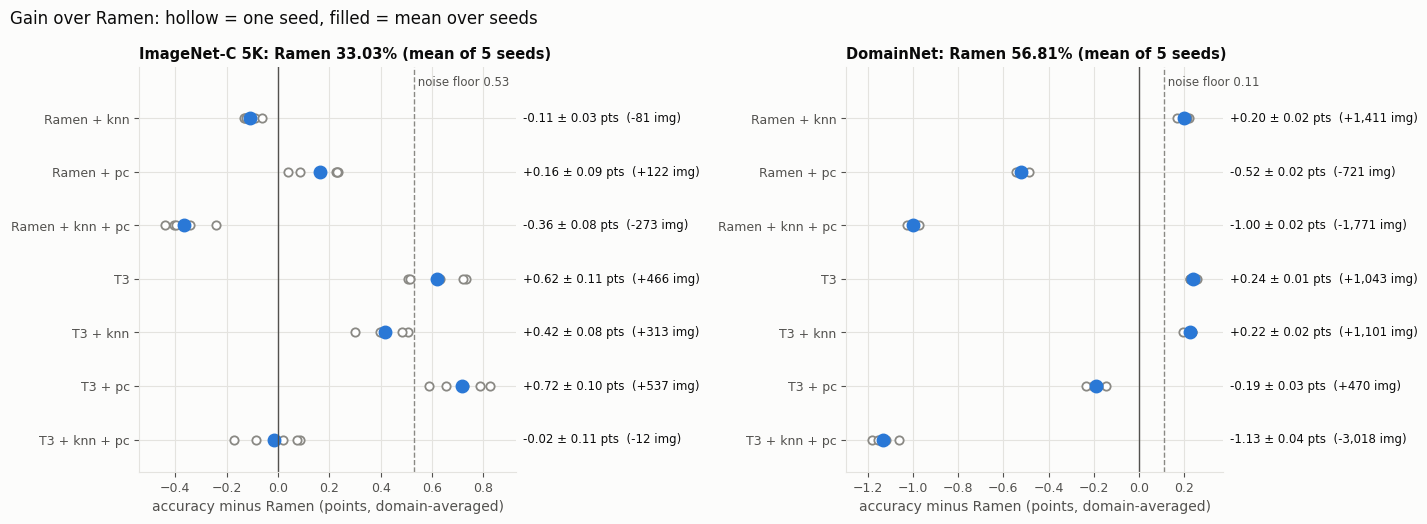

In [7]:
fig = stack.plot_seed_gains({ds: t[~t.posthoc] for ds, t in tables.items()})

In [8]:
ci = pd.concat({LABEL[ds]: t[~t.posthoc & (t.variant != 'Ramen')].set_index(['variant', 'seed'])[['gain', 'CI low', 'CI high']]
                for ds, t in tables.items()})
ci['CI excludes 0'] = ci['CI low'] > 0
ci.round(2).unstack('seed')['CI excludes 0']

seed                                0      1      2      3      4
              variant                                            
ImageNet-C 5K Ramen + knn       False  False  False  False  False
              Ramen + knn + pc  False  False  False  False  False
              Ramen + pc        False  False  False  False  False
              T3                 True   True   True   True   True
              T3 + knn           True   True   True   True   True
              T3 + knn + pc     False  False  False  False  False
              T3 + pc            True   True   True   True   True
DomainNet     Ramen + knn        True   True   True   True   True
              Ramen + knn + pc  False  False  False  False  False
              Ramen + pc        False  False  False  False  False
              T3                 True   True   True   True   True
              T3 + knn           True   True   True   True   True
              T3 + knn + pc     False  False  False  False  False
              T3 + pc           False  False  False  False  False

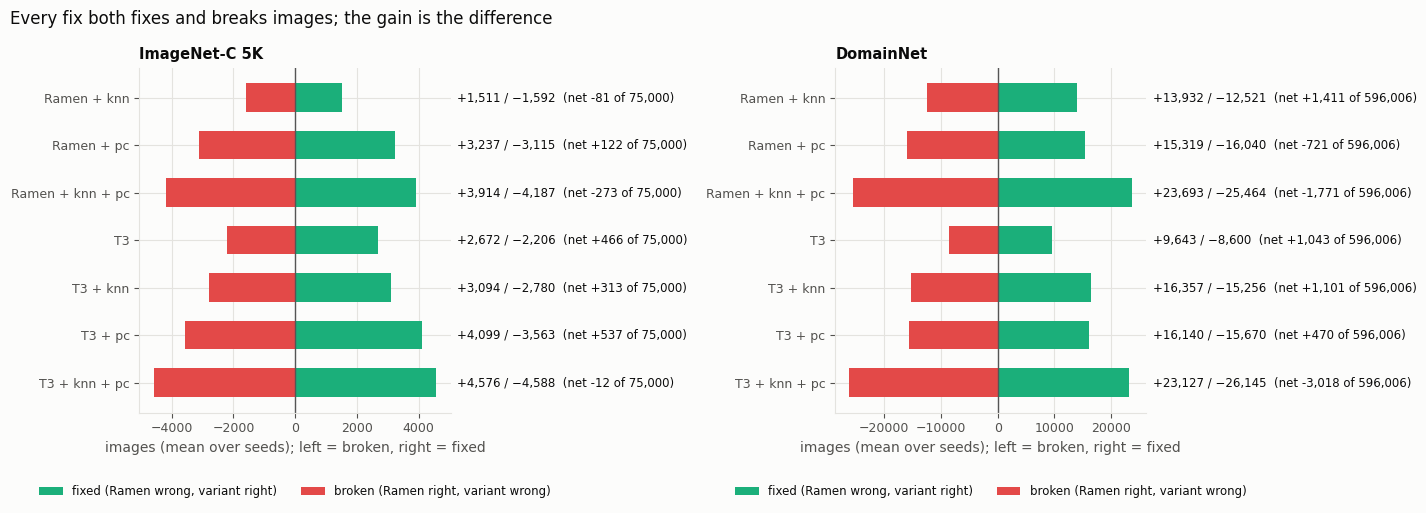

In [9]:
fig = stack.plot_fixed_broken({ds: t[~t.posthoc] for ds, t in tables.items()})

## 5. Does the stack add up?

Per seed: the full stack's gain vs the sum of the three single fixes (T3 alone, knn on Ramen, pc on Ramen). Stack − sum < 0 means the fixes overlap: partly correct the same images.

In [10]:
pd.concat({LABEL[ds]: additivity(ds, t[~t.posthoc]) for ds, t in tables.items()}).round(2)

T3   knn    pc  sum of parts  full stack  stack - sum
              seed                                                         
ImageNet-C 5K 0     0.51 -0.09  0.23          0.64       -0.17        -0.82
              1     0.51 -0.13  0.09          0.47       -0.09        -0.56
              2     0.73 -0.13  0.23          0.83        0.09        -0.74
              3     0.72 -0.13  0.23          0.82        0.07        -0.75
              4     0.63 -0.06  0.04          0.61        0.02        -0.59
DomainNet     0     0.25  0.19 -0.53         -0.10       -1.18        -1.08
              1     0.25  0.17 -0.49         -0.06       -1.06        -1.00
              2     0.25  0.22 -0.52         -0.05       -1.15        -1.09
              3     0.23  0.21 -0.54         -0.10       -1.12        -1.02
              4     0.22  0.21 -0.52         -0.09       -1.15        -1.06

## 6. Per domain

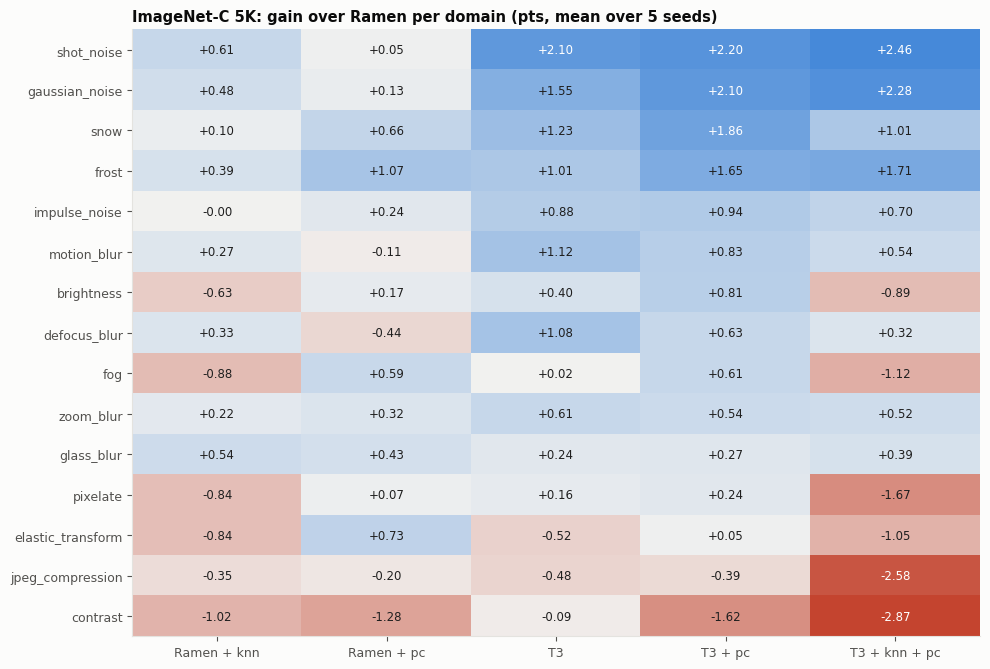

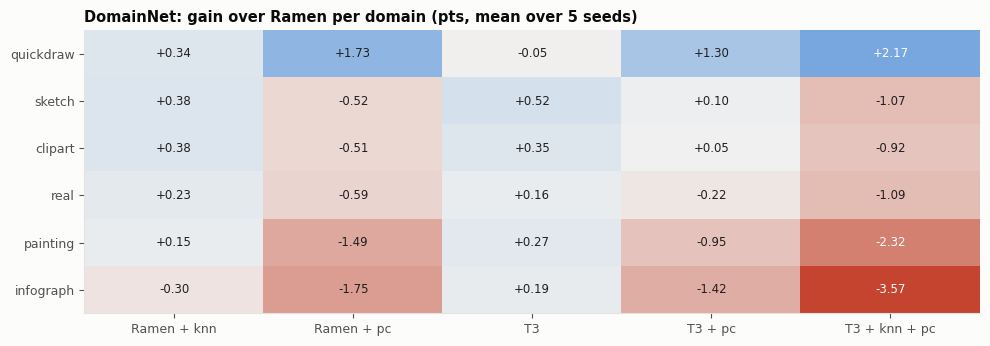

In [11]:
for ds in DATASETS:
    fig = stack.plot_domain_gain(ds)

## 7. Post-hoc: weaker prior correction

**Post-hoc** (λ chosen after the earlier DomainNet failure, not pre-registered). The uniform target is wrong on both datasets: ImageNet-C 5K has 0–180 images per class, and DomainNet's domains are strongly imbalanced. A smaller λ trusts the uniform target less.

In [12]:
rows = {}
for ds, t in tables.items():
    for v, g in t[t.variant.str.contains('pc')].groupby('variant'):
        rows[(LABEL[ds], v)] = {'gain mean': g.gain.mean(), 'gain std': g.gain.std(), 'positive': f'{(g.gain > 0).sum()}/{len(g)}',
                                'above floor': f'{(g.gain > NOISE_FLOOR[ds]).sum()}/{len(g)}', 'post-hoc': bool(g.posthoc.iloc[0])}
pd.DataFrame(rows).T.astype({'gain mean': float, 'gain std': float}).round(2)

gain mean  gain std positive above floor post-hoc
ImageNet-C 5K Ramen + knn + pc               -0.36      0.08      0/5         0/5    False
              Ramen + knn + pc(lam=0.5)       0.53      0.07      5/5         3/5     True
              Ramen + knn + pc(lam=1)         0.80      0.06      5/5         5/5     True
              Ramen + pc                      0.16      0.09      5/5         0/5    False
              Ramen + pc(lam=0.5)             0.43      0.05      5/5         0/5     True
              Ramen + pc(lam=1)               0.66      0.06      5/5         5/5     True
              T3 + knn + pc                  -0.02      0.11      3/5         0/5    False
              T3 + knn + pc(lam=0.5)          1.00      0.10      5/5         5/5     True
              T3 + knn + pc(lam=1)            1.15      0.07      5/5         5/5     True
              T3 + pc                         0.72      0.10      5/5         5/5    False
              T3 + pc(lam=0.5)                0.96      0.13      5/5         5/5     True
              T3 + pc(lam=1)                  1.13      0.10      5/5         5/5     True
DomainNet     Ramen + knn + pc               -1.00      0.02      0/5         0/5    False
              Ramen + knn + pc(lam=0.5)       0.40      0.02      5/5         5/5     True
              Ramen + knn + pc(lam=1)         0.32      0.01      5/5         5/5     True
              Ramen + pc                     -0.52      0.02      0/5         0/5    False
              Ramen + pc(lam=0.5)             0.19      0.01      5/5         5/5     True
              Ramen + pc(lam=1)               0.20      0.02      5/5         5/5     True
              T3 + knn + pc                  -1.13      0.04      0/5         0/5    False
              T3 + knn + pc(lam=0.5)          0.36      0.02      5/5         5/5     True
              T3 + knn + pc(lam=1)            0.24      0.01      5/5         5/5     True
              T3 + pc                        -0.19      0.03      0/5         0/5    False
              T3 + pc(lam=0.5)                0.39      0.01      5/5         5/5     True
              T3 + pc(lam=1)                  0.41      0.01      5/5         5/5     True

## 8. Mechanism: what does kNN average over?

Share of the neighbour weight (mean over images after the first batch) that falls on images with the same **true** class, the same domain, and, on ImageNet-C, the **same base photo under another corruption**. Labels are used only to describe the neighbours, never by the method. A large same-base-image share means kNN smoothing partly exploits a quirk of corruption benchmarks, where every photo appears 15 times.

In [13]:
diag = pd.concat({LABEL[ds]: collect(ds, 'knn_diag').set_index('seed') for ds in DATASETS})
diag[[c for c in diag.columns if c.startswith('same')]].round(1)

same true class  same domain  same base image
              seed                                               
ImageNet-C 5K 0                25.4         67.0             19.0
              1                25.4         66.9             19.0
              2                25.4         67.0             19.0
              3                25.4         67.0             19.0
              4                25.4         67.0             19.0
DomainNet     0                54.5         85.5              NaN
              1                54.5         85.5              NaN
              2                54.4         85.6              NaN
              3                54.5         85.5              NaN
              4                54.5         85.5              NaN

### Why kNN and λ = 2 prior correction clash

pc adds the same log-prior shift to every image's logits. Whether that flips the prediction depends on the image's top-1 vs top-2 log-margin. kNN smoothing averages each prediction with its neighbours', which shrinks that margin, so the same shift flips more predictions, and fixes and breaks nearly cancel (section 4). Below: the median log(p1/p2) and the share of predictions pc (λ = 2) changes, without and with smoothing (mean over seeds).

In [14]:
m = diag[[c for c in diag.columns if 'log(p1/p2)' in c or 'pc flips' in c]].groupby(level=0).mean().T
m.index = pd.MultiIndex.from_tuples([tuple(i.split(': ')) for i in m.index], names=['run', 'quantity'])
m.unstack('quantity').round(2)

DomainNet                ImageNet-C 5K           
quantity    median log(p1/p2) pc flips % median log(p1/p2) pc flips %
run                                                                  
Ramen                    2.27      19.74              0.86      31.32
Ramen + knn              1.61      24.36              0.69      37.80
T3                       3.36      17.33              1.09      28.49
T3 + knn                 1.94      23.24              0.80      35.36

## 9. Interpretation

**The pre-registered hypothesis is rejected.** The full stack (T3 + knn + pc at λ = 2) does not beat Ramen on either dataset: ImageNet-C −0.02 ± 0.11 pts (positive on 3/5 seeds, floor 0.53), DomainNet −1.13 ± 0.04 (0/5, floor 0.11). It is worse than T3 alone on both.

**What each piece does on the large-label datasets (pre-registered settings, mean ± std over seeds 0–4):**

| | ImageNet-C 5K (floor 0.53) | DomainNet (floor 0.11) |
|---|---|---|
| T3 | +0.62 ± 0.11 (3/5 above floor) | +0.24 ± 0.01 (5/5) |
| knn on Ramen | −0.11 ± 0.03 (0/5 positive) | +0.20 ± 0.02 (5/5 above floor, held-out) |
| pc (λ = 2) on Ramen | +0.16 ± 0.09 | −0.52 ± 0.02 |
| T3 + knn | +0.42 ± 0.08 | +0.22 ± 0.02 |
| T3 + pc | **+0.72 ± 0.10 (5/5 above floor)** | −0.19 ± 0.03 |
| T3 + knn + pc | −0.02 ± 0.11 | −1.13 ± 0.04 |

- **No pre-registered combination wins on both datasets.** T3 + pc clears the ImageNet-C floor on every seed, but T3 was tuned on ImageNet-C seed 0, so that number is not held-out, and the same combination loses on DomainNet. T3 alone is still the best pre-registered result that holds on both.
- **kNN smoothing helps only where neighbours share the true class.** On DomainNet 54% of the neighbour weight falls on the query's true class and knn gives +0.20. On ImageNet-C only 25% does (19% is the same photo under another corruption), and knn hurts on all 5 seeds. With 1,000 classes and severity-5 corruptions, zero-shot features are too degraded for a feature-space vote. On DomainNet, T3 and knn do not add up: +0.22 together vs +0.24 and +0.20 alone, so they fix largely the same images.
- **kNN and pc at λ = 2 clash on both datasets** (stack − sum of parts: −0.56 to −0.82 on ImageNet-C, about −1.0 on DomainNet). Smoothing shrinks each image's top-1/top-2 log-margin (median 0.86 → 0.69 on ImageNet-C, 2.27 → 1.61 on DomainNet), so the same log-prior shift flips more predictions: 31 → 38% and 20 → 24% of all images. Most of the extra flips are breaks. λ = 2 is too strong once outputs are smoothed.
- **λ = 2 with a uniform target is the weak link.** Neither dataset has uniform classes (ImageNet-C 5K: 0–180 images per class; DomainNet: strongly imbalanced). On DomainNet, T3 + pc gains +1.30 on quickdraw but loses −1.42 on infograph and −0.95 on painting. It adds +470 images pooled but loses −0.19 domain-averaged.

**Post-hoc (λ chosen after seeing these results; not evidence yet):** T3 + pc with **λ = 1** clears both floors on all 5 seeds: ImageNet-C +1.13 ± 0.10 (+846 images), DomainNet +0.41 ± 0.01 (+2,818 images). λ = 0.5 is close (+0.96 / +0.39), so the result is not a knife-edge in λ. Adding kNN on top adds nothing on ImageNet-C (+1.15) and costs 0.17 on DomainNet (+0.24).

**Caveats.** Seeds change only the stream order of the same images, so the five seeds rule out stream-order luck, not overfitting to these two datasets. T3 on ImageNet-C is not held-out. Every λ = 1 / 0.5 number is post-hoc.

**Next step.** Pre-register **T3 + pc(λ = 1)** (no kNN) and test it on a dataset none of these settings was tuned on. It needs a large label space, because T3 only helps there. ImageNet-R / ImageNet-Sketch / ImageNet-V2 would need a download. The cheap fallback is re-scoring CIFAR-100-C and EuroSAT with λ = 1 to check it doesn't break the small-label datasets where λ = 2 was tuned. If λ = 1 holds on a fresh dataset, the next lever is the uniform target: estimate the class prior instead of assuming it, possibly per cluster (direction 2 of the earlier plan).


## 10. Glossary

| Term | Meaning |
|---|---|
| Ramen | CLIP zero-shot + a per-class memory of (feature, entropy gradient); each batch takes one signSGD step built from retrieved memory entries, predicts, and resets |
| NoAdapt / zero-shot | plain CLIP with class-name prompts, no adaptation |
| T3 | zero-shot-weighted active set: each class queue's contribution weighted by the query's zero-shot probability at temperature 3 (RamenActive) |
| pc (prior correction) | subtract λ·log(estimated predicted-class share / uniform) from the logits, so over-predicted classes are pushed down |
| knn (kNN smoothing) | mix a prediction 50/50 with the predictions on the 10 most similar earlier images |
| domain-averaged accuracy | mean of the per-domain accuracies (headline metric; differs from pooled accuracy on DomainNet, whose domains have unequal sizes) |
| noise floor | 2 × (max − min) of Ramen's domain-averaged accuracy over seeds 0–4: deliberately strict; a gain must be large compared with how much the baseline moves with the stream order |
| fixed / broken vs Ramen | images Ramen gets wrong that the variant gets right / and the reverse |
| pre-registered / post-hoc | settings fixed before seeing these datasets / chosen after |
| cluster bootstrap CI | 95% interval from resampling whole clusters of correlated images (one base image appears under all 15 corruptions) |
| same base image | on ImageNet-C a neighbour that is the same original photo under a different corruption |